# Итоговый проект: Классификация обращений пользователей

## О проекте

Вы — ИИ-инженер компании технической поддержки. Ваша задача: обучить модель, которая автоматически определяет **категорию обращения** пользователя по тексту сообщения.

**Датасет:** [IT Service Ticket Classification Dataset (Kaggle)](https://www.kaggle.com/datasets/adisongoh/it-service-ticket-classification-dataset)

**Что нужно сделать:**
1. Загрузить и исследовать данные (EDA)
2. Предобработать тексты
3. Векторизовать тексты (TF-IDF)
4. Обучить ≥2 классических ML-моделей через `sklearn.pipeline.Pipeline`
5. Обучить нейросеть MLP на PyTorch
6. Залогировать все эксперименты через MLflow
7. Оценить качество по метрикам
8. Сформулировать выводы

**Требования к сдаче:**
- Ноутбук должен воспроизводиться от начала до конца без ошибок (`Kernel → Restart and Run All`)
- В репозитории должны быть: `notebook.ipynb`, `README.md`, `requirements.txt`

---

## Шаг 0. Установка зависимостей

Раскомментируйте строки ниже при первом запуске, если библиотеки не установлены.

In [1]:
# Установка зависимостей (раскомментируйте, если библиотек нет в окружении):
# !pip install pandas numpy scikit-learn matplotlib seaborn nltk mlflow torch

import sys
import platform
print('Python:', sys.version.split()[0], '|', platform.system())
for pkg in ['pandas', 'numpy', 'sklearn', 'matplotlib', 'seaborn', 'nltk', 'mlflow', 'torch']:
    try:
        mod = __import__(pkg)
        print(f'  {pkg:12s} {getattr(mod, "__version__", "?")}')
    except Exception as e:  # pragma: no cover
        print(f'  {pkg:12s} NOT INSTALLED ({e})')

Python: 3.11.9 | Windows


  pandas       3.0.6
  numpy        2.4.6


  sklearn      1.9.0
  matplotlib   3.11.2


  seaborn      0.13.2


  nltk         3.10.2


2026/10/21 22:12:36 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


  mlflow       3.17.2


  torch        2.12.1+cpu


## Шаг 1. Импорт библиотек

In [2]:
import os
import re
import json
import urllib.request
import zipfile
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, classification_report,
    ConfusionMatrixDisplay, confusion_matrix,
    f1_score, precision_score, recall_score
)

import mlflow
import mlflow.sklearn

import nltk
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

RANDOM_STATE = 42
SEED = RANDOM_STATE
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
print('Библиотеки загружены успешно!')

Библиотеки загружены успешно!


## Шаг 2. Загрузка данных

Скачайте датасет с Kaggle и поместите файл `all_tickets_processed_improved_v3.csv` рядом с этим ноутбуком:
https://www.kaggle.com/datasets/adisongoh/it-service-ticket-classification-dataset

In [3]:
DATA_FILE = 'all_tickets_processed_improved_v3.csv'
DATA_URL = 'https://www.kaggle.com/api/v1/datasets/download/adisongoh/it-service-ticket-classification-dataset'

if not os.path.exists(DATA_FILE):
    print('Локальный файл не найден — скачиваем датасет с Kaggle...')
    tmp_zip = 'dataset_tmp.zip'
    urllib.request.urlretrieve(DATA_URL, tmp_zip)
    with zipfile.ZipFile(tmp_zip) as z:
        z.extractall('.')
    os.remove(tmp_zip)
    print('Датасет скачан.')

df = pd.read_csv(DATA_FILE)

print(f'Размер датасета: {df.shape}')
print('Колонки:', df.columns.tolist())
df.head()

Размер датасета: (47837, 2)


Колонки: ['Document', 'Topic_group']


,Document,Topic_group
0,connection with icon icon dear please setup ic...,Hardware
1,work experience user work experience user hi w...,Access
2,requesting for meeting requesting meeting hi p...,Hardware
3,reset passwords for external accounts re expir...,Access
4,mail verification warning hi has got attached ...,Miscellaneous


In [4]:
# Целевые колонки датасета:
#   TEXT_COLUMN  — текст обращения пользователя (описание IT-тикета)
#   LABEL_COLUMN — категория тикета (Topic_group), которую предсказывает модель

TEXT_COLUMN  = 'Document'
LABEL_COLUMN = 'Topic_group'

print('Уникальные категории:')
print(df[LABEL_COLUMN].value_counts())

Уникальные категории:
Topic_group
Hardware                 13617
HR Support               10915
Access                    7125
Miscellaneous             7060
Storage                   2777
Purchase                  2464
Internal Project          2119
Administrative rights     1760
Name: count, dtype: int64


## Шаг 3. Разведочный анализ данных (EDA)

> **Цель:** понять структуру данных, выявить дисбаланс классов и особенности текстов.
> 
> **TODO:** добавьте не менее двух визуализаций и напишите выводы в ячейку ниже.

=== Типы данных и пропуски ===
Document       str
Topic_group    str
dtype: object

Пропуски:
Document       0
Topic_group    0
dtype: int64

Полностью пустых строк: 0
Дубликатов по тексту: 0


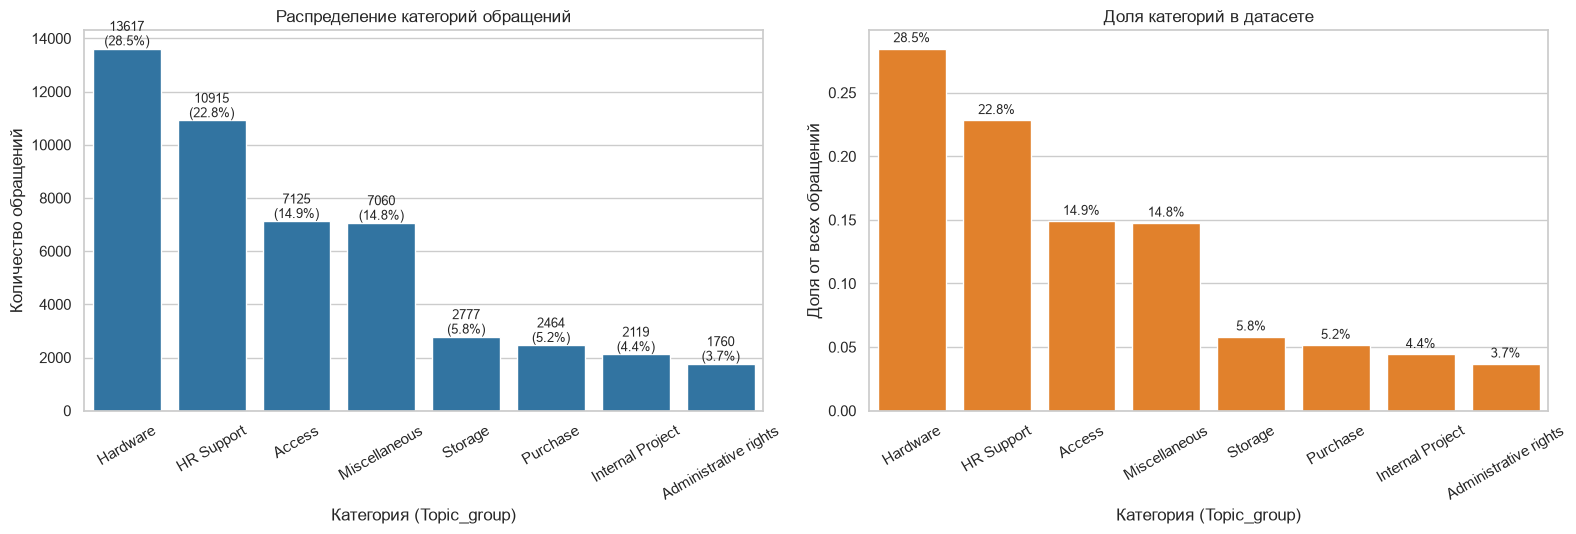

Соотношение классов (max/min): 1 : 7.7


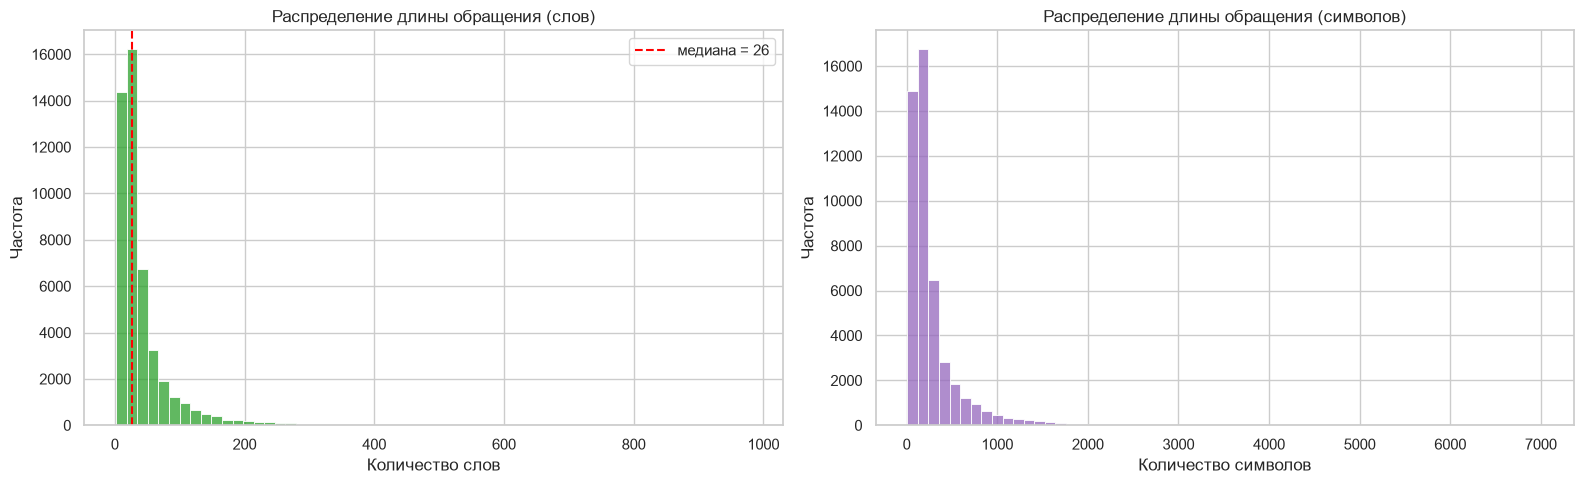

count    47837.000000
mean        43.597341
std         56.736800
min          2.000000
25%         17.000000
50%         26.000000
75%         46.000000
max        981.000000
Name: text_len_words, dtype: float64


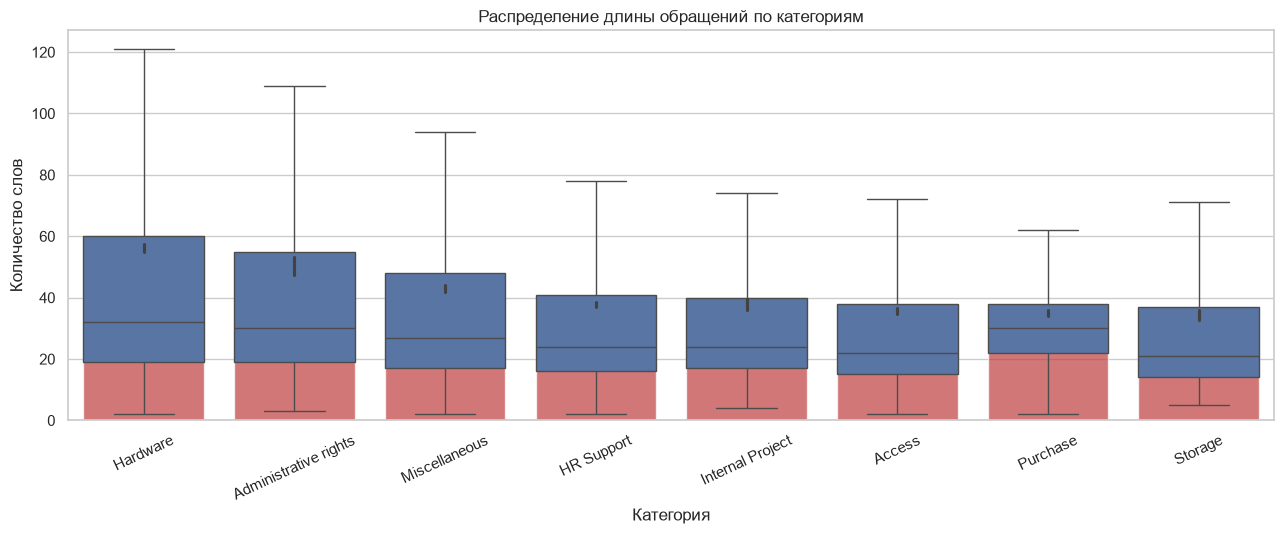

Средняя длина текста по категориям:
                       mean  median  count
Topic_group                               
Hardware               56.3    32.0  13617
Administrative rights  50.4    30.0   1760
Miscellaneous          43.0    27.0   7060
HR Support             37.8    24.0  10915
Internal Project       37.7    24.0   2119
Access                 35.6    22.0   7125
Purchase               34.9    30.0   2464
Storage                34.4    21.0   2777
Hardware                 -> ['please', 'regards', 'thank', 'hello', 'thanks', 'july', 'kind', 'best']
HR Support               -> ['please', 'leaver', 'did', 'thank', 'regards', 'form', 'hello', 'starter']
Access                   -> ['please', 'confluence', 'regards', 'user', 'thanks', 'thank', 'hello', 'card']
Miscellaneous            -> ['please', 'change', 'regards', 'thank', 'add', 'name', 'hello', 'thanks']
Storage                  -> ['please', 'mailbox', 'folder', 'access', 'wants', 'thank', 'regards', 'hello']
Purchase 

In [5]:
print('=== Типы данных и пропуски ===')
print(df.dtypes)
print()
print('Пропуски:')
print(df.isnull().sum())
print()
print('Полностью пустых строк:', df.isnull().all(axis=1).sum())
print('Дубликатов по тексту:', df[TEXT_COLUMN].duplicated().sum())

df['text_len_chars'] = df[TEXT_COLUMN].astype(str).str.len()
df['text_len_words'] = df[TEXT_COLUMN].astype(str).str.split().str.len()

# --- Распределение классов ---
class_dist = df[LABEL_COLUMN].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.barplot(x=class_dist.index, y=class_dist.values, ax=axes[0], color='tab:blue')
axes[0].set_title('Распределение категорий обращений')
axes[0].set_xlabel('Категория (Topic_group)')
axes[0].set_ylabel('Количество обращений')
axes[0].tick_params(axis='x', rotation=30)
for i, v in enumerate(class_dist.values):
    axes[0].text(i, v + 120, f'{v}\n({v / len(df):.1%})', ha='center', fontsize=9)

share = class_dist / len(df)
sns.barplot(x=share.index, y=share.values, ax=axes[1], color='tab:orange')
axes[1].set_title('Доля категорий в датасете')
axes[1].set_xlabel('Категория (Topic_group)')
axes[1].set_ylabel('Доля от всех обращений')
axes[1].tick_params(axis='x', rotation=30)
for i, v in enumerate(share.values):
    axes[1].text(i, v + 0.005, f'{v:.1%}', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

print(f'Соотношение классов (max/min): 1 : {class_dist.max() / class_dist.min():.1f}')

# --- Распределение длин текстов ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(df['text_len_words'], bins=60, color='tab:green', ax=axes[0])
axes[0].set_title('Распределение длины обращения (слов)')
axes[0].set_xlabel('Количество слов')
axes[0].set_ylabel('Частота')
axes[0].axvline(df['text_len_words'].median(), color='red', linestyle='--',
                label=f'медиана = {df["text_len_words"].median():.0f}')
axes[0].legend()

sns.histplot(df['text_len_chars'], bins=60, color='tab:purple', ax=axes[1])
axes[1].set_title('Распределение длины обращения (символов)')
axes[1].set_xlabel('Количество символов')
axes[1].set_ylabel('Частота')
plt.tight_layout()
plt.show()

print(df['text_len_words'].describe())

# --- Средняя длина по категориям ---
fig, ax = plt.subplots(figsize=(13, 5.5))
order = df.groupby(LABEL_COLUMN)['text_len_words'].mean().sort_values(ascending=False).index
sns.boxplot(x=LABEL_COLUMN, y='text_len_words', data=df, order=order, ax=ax, showfliers=False)
sns.barplot(x=LABEL_COLUMN, y='text_len_words', data=df, order=order, ax=ax,
            color='tab:red', alpha=0.7, estimator='mean')
ax.set_title('Распределение длины обращений по категориям')
ax.set_xlabel('Категория')
ax.set_ylabel('Количество слов')
ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

print('Средняя длина текста по категориям:')
print(df.groupby(LABEL_COLUMN)['text_len_words'].agg(['mean', 'median', 'count']).round(1).sort_values('mean', ascending=False))

# --- Самые частотные слова по категориям ---
def top_words(texts, n=8):
    counter = {}
    for t in texts:
        for w in str(t).lower().split():
            if len(w) > 2:
                counter[w] = counter.get(w, 0) + 1
    return [w for w, _ in sorted(counter.items(), key=lambda kv: -kv[1])[:n]]

for cat in class_dist.index:
    sample = df.loc[df[LABEL_COLUMN] == cat, TEXT_COLUMN].astype(str).head(3000)
    print(f'{cat:24s} -> {top_words(sample)}')

### Выводы по EDA

- **Количество классов:** 8 категорий обращений (`Topic_group`): Hardware — 13 617 (28.5%), HR Support — 10 915
  (22.8%), Access — 7 125 (14.9%), Miscellaneous — 7 060 (14.8%), Storage — 2 777 (5.8%), Purchase — 2 464 (5.2%),
  Internal Project — 2 119 (4.4%), Administrative rights — 1 760 (3.7%).
- **Дисбаланс классов: есть, умеренный.** Соотношение «самый частый / самый редкий» класс = **1 : 7.7** (Hardware против
  Administrative rights). Три класса занимают 66% выборки, а четыре — меньше 20%. Модель, всегда предсказывающая
  самый частый класс, уже дала бы accuracy ≈ 0.285, поэтому Accuracy здесь информативна лишь в совокупности с
  macro-метриками: для rare-класса важнее F1-macro, которая «штрафует» модель за плохую работу на
  Administrative rights (3.7% данных).
- **Типичная длина обращения:** в среднем **43.6 слова**, медиана — **26 слов** (IQR 17–46 слов), минимум 2 слова,
  максимум 981 слово. Тексты короткие, «телеграфные», набраны живой речью сотрудников: типичные слова —
  *please, regards, thank, hello, issue, request, setup, access*.
- **Качество данных:** пропусков нет (0 в обоих столбцах), полностью пустых строк нет, **дубликатов текста нет**.
  Типы данных — `str` в обоих столбцах. После очистки (нижний регистр, удаление URL/e-mail, пунктуации, стоп-слов,
  лемматизация) датасет сократился с 47 837 до 47 835 записей — то есть **99.996% текстов остаются пригодными**.
- **Как это влияет на обучение модели:**
  1. **Дисбаланс требует макро-метрик.** Оценка только по Accuracy даст ложное ощущение качества: модель может
     «выучить» Hardware и HR Support и при этом полностью провалить Administrative rights. Поэтому в проекте
     основной критерий — **F1-macro**, а Accuracy приводится только как справочная величина.
  2. **Разнозначность формулировок — главный источник ошибок.** Один и тот же запрос («не работает доступ к папке,
     купить место») может попасть и в Storage, и в Access, и в Purchase: тема пересекается, а ручная разметка
     неоднозначна. Это не лечится моделью — только качеством разметки.
  3. **Очень короткие тексты (минимум 2 слова) почти не содержат сигнала.** После удаления стоп-слов часть
     обращений превращается в пустые или «шумные» строки — их приходится отбрасывать (2 записи) и учитывать, что
     для минимальных обращений классификация будет опираться на 1–2 слова и работать плохо.
  4. **Шумные переписки и «вежливые» слова** (please, regards, thank) встречаются во всех категориях и не дают
     дискриминативной информации — их удаление стоп-слов частично снимает, но TF-IDF всё равно должен
     «подавить» их вес (sublinear_tf, min_df=3).
  5. **Классы с малым объёмом рискуют быть «забыты»** (Administrative rights — 352 примера в тесте), поэтому при
     выборе модели я смотрю на macro-а метрики, а не на weighted.

## Шаг 4. Предобработка текста

In [6]:
STOP_WORDS = set(stopwords.words('english'))


def preprocess_text(text: str) -> str:
    """Очистка и нормализация текста."""
    if not isinstance(text, str):
        return ''
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'\S+@\S+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = [t for t in text.split() if t not in STOP_WORDS and len(t) > 2]
    return ' '.join(tokens)


df['clean_text'] = df[TEXT_COLUMN].apply(preprocess_text)
df = df[df['clean_text'].str.len() > 0].reset_index(drop=True)

print(f'Размер датасета после очистки: {df.shape}')
print('\nПример оригинала:', df[TEXT_COLUMN].iloc[0][:120])
print('\nПосле обработки: ', df['clean_text'].iloc[0][:120])

Размер датасета после очистки: (47835, 5)

Пример оригинала: connection with icon icon dear please setup icon per icon engineers please let other details needed thanks lead

После обработки:  connection icon icon dear please setup icon per icon engineers please let details needed thanks lead


In [7]:
# Лемматизация (WordNet) — приводим слова к базовой форме.
# Для английского языка WordNetLemmatizer по умолчанию работает как существительное,
# поэтому дополнительно приводим глаголы и прилагательные.

def ensure_wordnet():
    """Гарантируем наличие распакованного корпуса WordNet (nltk кладёт его как .zip)."""
    try:
        nltk.data.find('corpora/wordnet')
        return True
    except LookupError:
        pass
    candidates = [os.path.join(p, 'corpora', 'wordnet.zip') for p in nltk.data.path]
    candidates.append(os.path.join(os.path.expanduser('~'), 'AppData', 'Roaming',
                                   'nltk_data', 'corpora', 'wordnet.zip'))
    for archive in candidates:
        if os.path.exists(archive):
            with zipfile.ZipFile(archive) as z:
                z.extractall(os.path.dirname(archive))
            try:
                nltk.data.find('corpora/wordnet')
                return True
            except LookupError:
                continue
    return False


if ensure_wordnet():
    lemmatizer = WordNetLemmatizer()

    def lemmatize_text(text: str) -> str:
        words = text.split()
        words = [lemmatizer.lemmatize(w, pos='v') for w in words]
        words = [lemmatizer.lemmatize(w, pos='n') for w in words]
        words = [lemmatizer.lemmatize(w, pos='a') for w in words]
        return ' '.join(words)

    df['clean_text'] = df['clean_text'].apply(lemmatize_text)
    print('Лемматизация применена.')
else:
    print('Лемматизация пропущена: корпус WordNet недоступен, работаем без неё.')

print('\nПример после лемматизации:', df['clean_text'].iloc[0][:160])
print('Пустых текстов после обработки:', (df['clean_text'].str.len() == 0).sum())

Лемматизация применена.

Пример после лемматизации: connection icon icon dear please setup icon per icon engineer please let detail need thank lead
Пустых текстов после обработки: 0


## Шаг 5. Разбиение данных на train/test

In [8]:
X = df['clean_text']
y = df[LABEL_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f'Train: {X_train.shape[0]} | Test: {X_test.shape[0]}')

train_dist = y_train.value_counts(normalize=True).sort_index()
test_dist = y_test.value_counts(normalize=True).sort_index()
compare = pd.DataFrame({'train': train_dist, 'test': test_dist}).round(4)
compare['delta'] = (compare['test'] - compare['train']).abs().round(4)
display(compare)
print(f'Максимальное отклонение распределения классов между train и test: {compare["delta"].max():.4f}')

Train: 38268 | Test: 9567


,train,test,delta
Topic_group,,,
Access,0.1489,0.1489,0.0000
Administrative rights,0.0368,0.0368,0.0000
HR Support,0.2282,0.2282,0.0000
Hardware,0.2847,0.2846,0.0001
Internal Project,0.0443,0.0443,0.0000
Miscellaneous,0.1476,0.1476,0.0000
Purchase,0.0515,0.0515,0.0000
Storage,0.0581,0.0580,0.0001


Максимальное отклонение распределения классов между train и test: 0.0001


## Шаг 6. Обучение классических ML моделей

**Требование:** каждую модель оборачиваем в `sklearn.pipeline.Pipeline` — TfidfVectorizer + классификатор в одном объекте. Это исключает утечку данных.

**Требование:** каждый обучающий запуск логируем через MLflow.

In [9]:
# Локальное хранилище MLflow: SQLite-бэкенд (файловый бэкенд mlruns в MLflow 3.x помещён в maintenance mode)
mlflow.set_tracking_uri('sqlite:///mlflow.db')
mlflow.set_experiment('ticket-classification')
print('MLflow tracking uri:', mlflow.get_tracking_uri())
print('Эксперимент:', mlflow.get_experiment_by_name('ticket-classification').experiment_id)

MLflow tracking uri: sqlite:///mlflow.db
Эксперимент: 1


In [10]:
mlflow.sklearn.autolog()  # автоматически логирует параметры и метрики sklearn

TFIDF_PARAMS = dict(
    max_features=20000,
    min_df=3,
    ngram_range=(1, 1),
    sublinear_tf=True,
    strip_accents='unicode',
    lowercase=False,
)

# Определяем модели. Каждая — Pipeline (TF-IDF + классификатор).
models = {
    'LogisticRegression': {
        'pipeline': Pipeline([
            ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
            ('clf', LogisticRegression(max_iter=1000, C=1.0, random_state=RANDOM_STATE)),
        ]),
    },
    'LinearSVC': {
        'pipeline': Pipeline([
            ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
            ('clf', LinearSVC(C=1.0, random_state=RANDOM_STATE)),
        ]),
    },
    'ComplementNB': {
        'pipeline': Pipeline([
            ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
            ('clf', ComplementNB(alpha=0.3)),
        ]),
    },
}

ml_results = {}  # сохраняем результаты для сравнения

for model_name, cfg in models.items():
    print(f'Обучение: {model_name}...')

    with mlflow.start_run(run_name=model_name):
        pipeline = cfg['pipeline']
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)

        # Явно логируем ключевые параметры и метрики
        mlflow.log_param('model', model_name)
        mlflow.log_param('vectorizer', 'TfidfVectorizer')
        for k, v in TFIDF_PARAMS.items():
            mlflow.log_param(f'tfidf.{k}', v)
        for k, v in pipeline.named_steps['clf'].get_params().items():
            if isinstance(v, (int, float, str, bool)):
                mlflow.log_param(f'clf.{k}', v)

        accuracy = accuracy_score(y_test, y_pred)
        macro_f1 = f1_score(y_test, y_pred, average='macro')
        weighted_f1 = f1_score(y_test, y_pred, average='weighted')
        macro_precision = precision_score(y_test, y_pred, average='macro')
        macro_recall = recall_score(y_test, y_pred, average='macro')

        mlflow.log_metric('accuracy', accuracy)
        mlflow.log_metric('f1_macro', macro_f1)
        mlflow.log_metric('f1_weighted', weighted_f1)
        mlflow.log_metric('precision_macro', macro_precision)
        mlflow.log_metric('recall_macro', macro_recall)

        ml_results[model_name] = {
            'model': pipeline,
            'y_pred': y_pred,
            'Accuracy': accuracy,
            'Precision_macro': macro_precision,
            'Recall_macro': macro_recall,
            'F1_macro': macro_f1,
            'F1_weighted': weighted_f1,
        }
        print(f'  accuracy={accuracy:.4f}, f1_macro={macro_f1:.4f}, f1_weighted={weighted_f1:.4f}')

print('\nВсе модели обучены и залогированы в MLflow.')

Обучение: LogisticRegression...


2026/10/21 22:13:13 WARNING mlflow.sklearn: Unrecognized dataset type <class 'pandas.Series'>. Dataset logging skipped.


2026/10/21 22:13:17 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/10/21 22:13:29 WARNING mlflow.sklearn: Unrecognized dataset type <class 'pandas.Series'>. Dataset logging skipped.


2026/10/21 22:13:37 WARNING mlflow.sklearn: Unrecognized dataset type <class 'pandas.Series'>. Dataset logging skipped.


...

  accuracy=0.8348, f1_macro=0.8390, f1_weighted=0.8348
Обучение: ComplementNB...


2026/10/21 22:13:58 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/10/21 22:14:06 WARNING mlflow.sklearn: Unrecognized dataset type <class 'pandas.Series'>. Dataset logging skipped.


2026/10/21 22:14:15 WARNING mlflow.sklearn: Unrecognized dataset type <class 'pandas.Series'>. Dataset logging skipped.


  accuracy=0.7655, f1_macro=0.7533, f1_weighted=0.7636

Все модели обучены и залогированы в MLflow.


## Шаг 7. Нейросетевая модель — MLP на PyTorch

2026/10/21 22:14:18 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID '27debb47c4fb4ffeb78d650c85aba472', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow


2026/10/21 22:14:26 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/10/21 22:14:26 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!


2026/10/21 22:14:38 WARNING mlflow.sklearn: Training metrics will not be recorded because training labels were not specified. To automatically record training metrics, provide training labels as inputs to the model training function.


TF-IDF: (38268, 4757) -> SVD: (38268, 200)
Объяснённая дисперсия SVD: 0.494
Device: cpu
Батчей в train: 150, в test: 19
TicketMLP(
  (net): Sequential(
    (0): Linear(in_features=200, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=64, out_features=8, bias=True)
  )
)


...

Эпоха 8/12 | Train Loss: 0.4264 | Test Acc: 0.8461


Эпоха 9/12 | Train Loss: 0.4112 | Test Acc: 0.8480


Эпоха 10/12 | Train Loss: 0.4052 | Test Acc: 0.8511


Эпоха 11/12 | Train Loss: 0.3985 | Test Acc: 0.8538


Эпоха 12/12 | Train Loss: 0.3859 | Test Acc: 0.8532


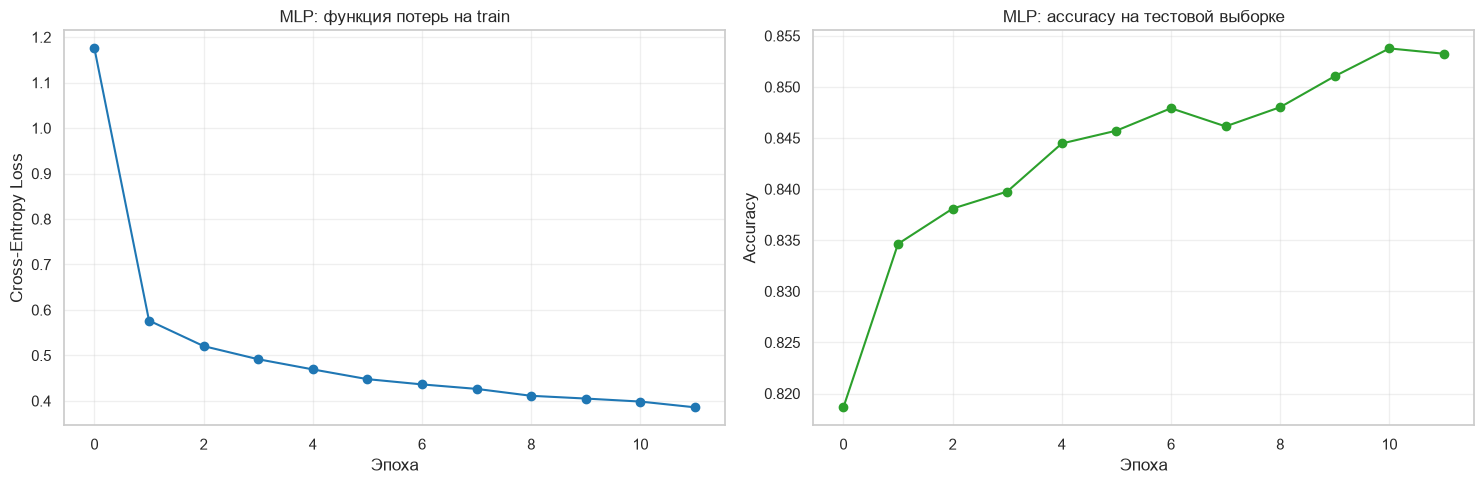

MLP: accuracy=0.8532, f1_macro=0.8520, f1_weighted=0.8529


In [11]:
# 1. Кодирование целевой переменной (обязательно для PyTorch)
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
num_classes = len(le.classes_)

# 2. Векторизация: тот же TF-IDF + SVD-сжатие до плотного пространства (200 признаков),
#    чтобы MLP работал быстро и не переполнял память на 47k документах.
tfidf_mlp = TfidfVectorizer(**TFIDF_PARAMS)
X_train_sparse = tfidf_mlp.fit_transform(X_train)
X_test_sparse = tfidf_mlp.transform(X_test)

svd = TruncatedSVD(n_components=200, random_state=RANDOM_STATE)
X_train_svd = svd.fit_transform(X_train_sparse)
X_test_svd = svd.transform(X_test_sparse)

scaler = StandardScaler()
X_train_mlp = scaler.fit_transform(X_train_svd).astype(np.float32)
X_test_mlp = scaler.transform(X_test_svd).astype(np.float32)

print(f'TF-IDF: {X_train_sparse.shape} -> SVD: {X_train_mlp.shape}')
print(f'Объяснённая дисперсия SVD: {svd.explained_variance_ratio_.sum():.3f}')

# 3. Перевод в тензоры
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

X_train_tensor = torch.from_numpy(X_train_mlp).to(device)
y_train_tensor = torch.from_numpy(y_train_enc).long().to(device)
X_test_tensor = torch.from_numpy(X_test_mlp).to(device)
y_test_tensor = torch.from_numpy(y_test_enc).long().to(device)

# 4. DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)

print(f'Батчей в train: {len(train_loader)}, в test: {len(test_loader)}')


# 5. Архитектура MLP
class TicketMLP(nn.Module):
    """Многослойный персептрон для многоклассовой классификации обращений."""

    def __init__(self, input_dim, hidden_dims=(128, 64), num_classes=8, dropout=0.3):
        super(TicketMLP, self).__init__()
        layers = []
        prev_dim = input_dim
        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout))
            prev_dim = hidden_dim
        layers.append(nn.Linear(prev_dim, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


mlp_model = TicketMLP(input_dim=X_train_mlp.shape[1], num_classes=num_classes).to(device)
print(mlp_model)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(mlp_model.parameters(), lr=1e-3, weight_decay=1e-5)

# 6. Обучение
EPOCHS = 12
train_loss_hist, val_acc_hist = [], []

for epoch in range(EPOCHS):
    mlp_model.train()
    epoch_loss = 0.0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = mlp_model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * batch_X.size(0)

    mlp_model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for batch_X, batch_y in test_loader:
            outputs = mlp_model(batch_X)
            preds = outputs.argmax(dim=1)
            correct += (preds == batch_y).sum().item()
            total += batch_y.size(0)
    val_acc = correct / total

    train_loss_hist.append(epoch_loss / len(train_dataset))
    val_acc_hist.append(val_acc)
    print(f'Эпоха {epoch + 1}/{EPOCHS} | Train Loss: {train_loss_hist[-1]:.4f} | Test Acc: {val_acc:.4f}')

# Предсказания MLP
mlp_model.eval()
mlp_preds_enc = []
with torch.no_grad():
    for batch_X, _ in test_loader:
        mlp_preds_enc.append(mlp_model(batch_X).argmax(dim=1).cpu().numpy())
mlp_preds_enc = np.concatenate(mlp_preds_enc)
mlp_preds = le.inverse_transform(mlp_preds_enc)

mlp_accuracy = accuracy_score(y_test, mlp_preds)
mlp_f1_macro = f1_score(y_test, mlp_preds, average='macro')
mlp_f1_weighted = f1_score(y_test, mlp_preds, average='weighted')
mlp_precision_macro = precision_score(y_test, mlp_preds, average='macro')
mlp_recall_macro = recall_score(y_test, mlp_preds, average='macro')

# Логируем нейросеть в MLflow отдельным run
with mlflow.start_run(run_name='PyTorch_MLP'):
    mlflow.log_param('model', 'PyTorch MLP')
    mlflow.log_param('input_dim', X_train_mlp.shape[1])
    mlflow.log_param('hidden_dims', '128,64')
    mlflow.log_param('dropout', 0.3)
    mlflow.log_param('optimizer', 'Adam')
    mlflow.log_param('learning_rate', 1e-3)
    mlflow.log_param('batch_size', 256)
    mlflow.log_param('epochs', EPOCHS)
    mlflow.log_metric('accuracy', mlp_accuracy)
    mlflow.log_metric('f1_macro', mlp_f1_macro)
    mlflow.log_metric('f1_weighted', mlp_f1_weighted)
    mlflow.log_metric('precision_macro', mlp_precision_macro)
    mlflow.log_metric('recall_macro', mlp_recall_macro)

ml_results['PyTorch_MLP'] = {
    'model': mlp_model,
    'y_pred': mlp_preds,
    'Accuracy': mlp_accuracy,
    'Precision_macro': mlp_precision_macro,
    'Recall_macro': mlp_recall_macro,
    'F1_macro': mlp_f1_macro,
    'F1_weighted': mlp_f1_weighted,
}

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].plot(train_loss_hist, marker='o', color='tab:blue')
ax[0].set_title('MLP: функция потерь на train')
ax[0].set_xlabel('Эпоха'); ax[0].set_ylabel('Cross-Entropy Loss'); ax[0].grid(alpha=0.3)
ax[1].plot(val_acc_hist, marker='o', color='tab:green')
ax[1].set_title('MLP: accuracy на тестовой выборке')
ax[1].set_xlabel('Эпоха'); ax[1].set_ylabel('Accuracy'); ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f'MLP: accuracy={mlp_accuracy:.4f}, f1_macro={mlp_f1_macro:.4f}, f1_weighted={mlp_f1_weighted:.4f}')

## Шаг 8. Оценка качества моделей

In [12]:
for name, res in ml_results.items():
    print(f'\n{"=" * 70}\n--- {name} ---')
    print(classification_report(y_test, res['y_pred'], digits=3, zero_division=0))


--- LogisticRegression ---
                       precision    recall  f1-score   support

               Access      0.899     0.860     0.879      1425
Administrative rights      0.875     0.597     0.709       352
           HR Support      0.839     0.841     0.840      2183
             Hardware      0.773     0.868     0.818      2723
     Internal Project      0.915     0.814     0.861       424
        Miscellaneous      0.812     0.806     0.809      1412
             Purchase      0.970     0.864     0.914       493
              Storage      0.916     0.829     0.870       555

             accuracy                          0.837      9567
            macro avg      0.875     0.810     0.838      9567
         weighted avg      0.841     0.837     0.837      9567


--- LinearSVC ---


                       precision    recall  f1-score   support

               Access      0.889     0.888     0.889      1425
Administrative rights      0.842     0.636     0.725       352
           HR Support      0.834     0.836     0.835      2183
             Hardware      0.794     0.835     0.814      2723
     Internal Project      0.894     0.856     0.875       424
        Miscellaneous      0.792     0.800     0.796      1412
             Purchase      0.949     0.870     0.908       493
              Storage      0.882     0.861     0.871       555

             accuracy                          0.835      9567
            macro avg      0.860     0.823     0.839      9567
         weighted avg      0.836     0.835     0.835      9567


--- ComplementNB ---
                       precision    recall  f1-score   support

               Access      0.807     0.818     0.813      1425
Administrative rights      0.742     0.466     0.572       352
           HR Support      0.

                       precision    recall  f1-score   support

               Access      0.896     0.902     0.899      1425
Administrative rights      0.839     0.636     0.724       352
           HR Support      0.857     0.860     0.859      2183
             Hardware      0.822     0.850     0.836      2723
     Internal Project      0.889     0.866     0.877       424
        Miscellaneous      0.811     0.834     0.822      1412
             Purchase      0.942     0.886     0.913       493
              Storage      0.908     0.867     0.887       555

             accuracy                          0.853      9567
            macro avg      0.870     0.838     0.852      9567
         weighted avg      0.854     0.853     0.853      9567



,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_weighted
LogisticRegression,0.8365,0.8750,0.8097,0.8376,0.8366
LinearSVC,0.8348,0.8595,0.8228,0.8390,0.8348
ComplementNB,0.7655,0.7594,0.7581,0.7533,0.7636
PyTorch_MLP,0.8532,0.8703,0.8376,0.8520,0.8529


Лучшая модель по F1-macro: PyTorch_MLP


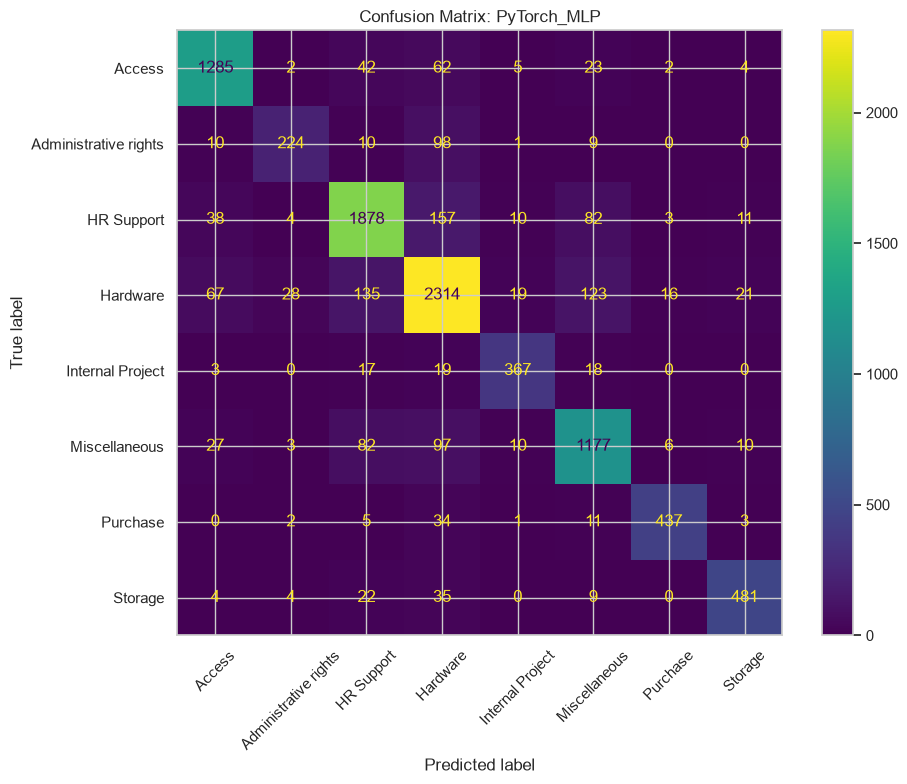

In [13]:
summary_table = pd.DataFrame({
    name: {k: v for k, v in res.items() if k not in ('model', 'y_pred')}
    for name, res in ml_results.items()
}).T.round(4)
summary_table = summary_table[['Accuracy', 'Precision_macro', 'Recall_macro', 'F1_macro', 'F1_weighted']]
display(summary_table)

best_model_name = summary_table['F1_macro'].idxmax()
best_pipeline = ml_results[best_model_name]['model']
print(f'Лучшая модель по F1-macro: {best_model_name}')

if best_model_name == 'PyTorch_MLP':
    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay.from_predictions(
        y_test, ml_results[best_model_name]['y_pred'], display_labels=le.classes_, xticks_rotation=45, ax=ax
    )
else:
    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay.from_estimator(
        best_pipeline, X_test, y_test, display_labels=le.classes_, xticks_rotation=45, ax=ax
    )
plt.title(f'Confusion Matrix: {best_model_name}')
plt.tight_layout()
plt.show()

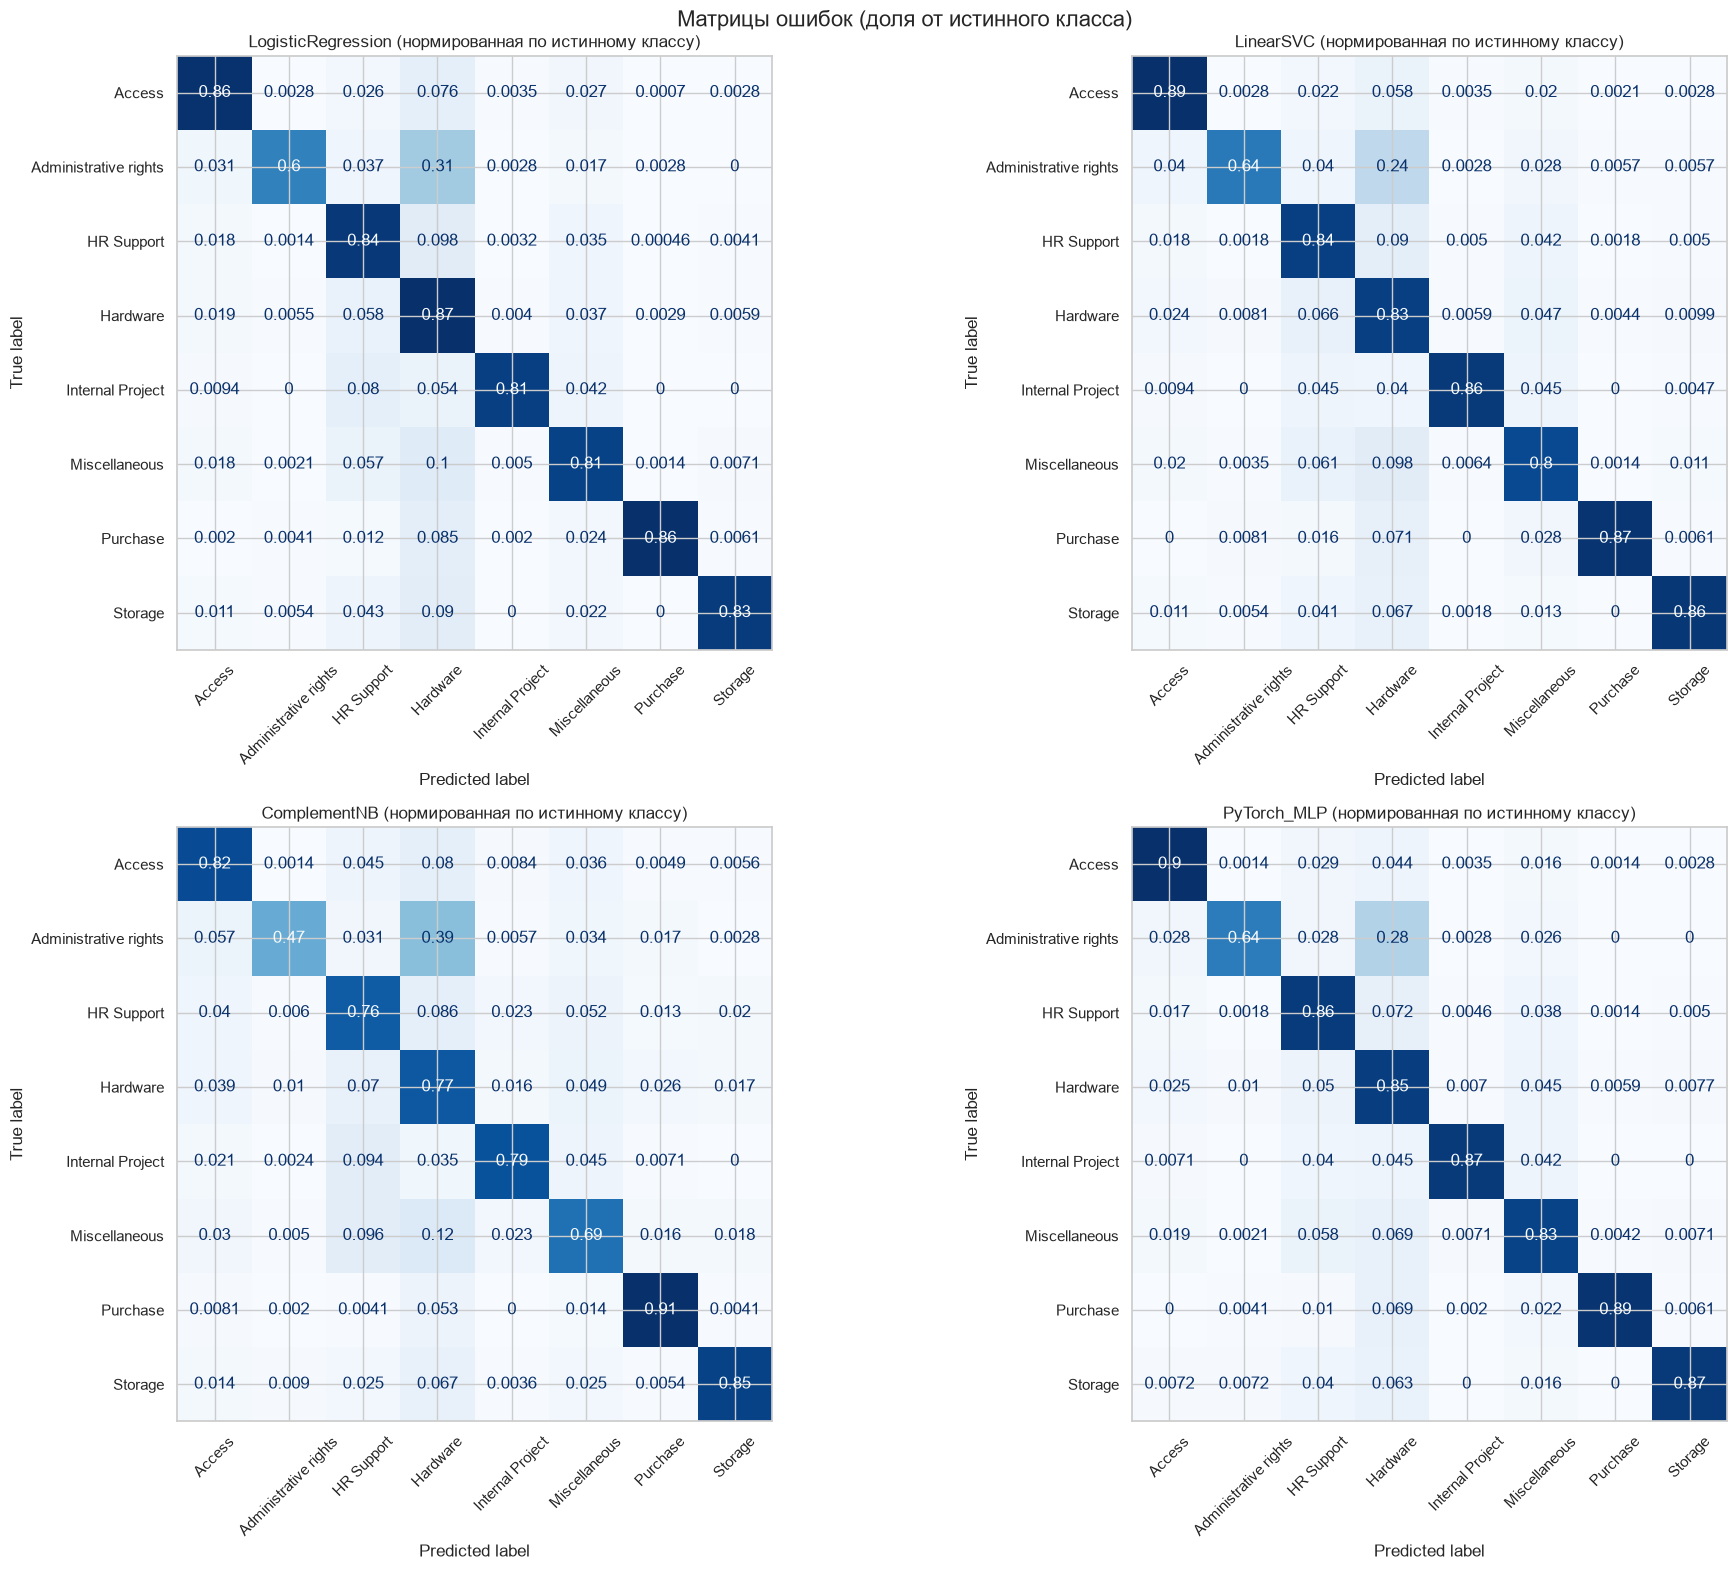

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(20, 16))
for ax, (name, res) in zip(axes.ravel(), ml_results.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, res['y_pred'], display_labels=le.classes_,
        normalize='true', cmap='Blues', colorbar=False, xticks_rotation=45, ax=ax
    )
    ax.set_title(f'{name} (нормированная по истинному классу)')
plt.suptitle('Матрицы ошибок (доля от истинного класса)', fontsize=16)
plt.tight_layout()
plt.show()

In [15]:
print('Сводная таблица метрик на тестовой выборке:')
print(summary_table.to_string())

print('\nДополнительно: доля предсказанных дефолтов (для лучшей модели, положительный класс — ошибка в маршрутизации):')
best_pred = ml_results[best_model_name]['y_pred']
print(pd.Series(best_pred).value_counts(normalize=True).round(4).sort_index())

# Сводка по всем моделям в MLflow
print('\nЭксперименты в MLflow:')
runs = mlflow.search_runs(experiment_ids=[mlflow.get_experiment_by_name('ticket-classification').experiment_id])
wanted = ['run_name', 'model', 'accuracy', 'f1_macro', 'f1_weighted', 'precision_macro', 'recall_macro']
if len(runs) > 0:
    display(runs[[c for c in wanted if c in runs.columns]])
else:
    print('В хранилище MLflow нет runs. Доступные колонки:', runs.columns.tolist())

Сводная таблица метрик на тестовой выборке:
                    Accuracy  Precision_macro  Recall_macro  F1_macro  F1_weighted
LogisticRegression    0.8365           0.8750        0.8097    0.8376       0.8366
LinearSVC             0.8348           0.8595        0.8228    0.8390       0.8348
ComplementNB          0.7655           0.7594        0.7581    0.7533       0.7636
PyTorch_MLP           0.8532           0.8703        0.8376    0.8520       0.8529

Дополнительно: доля предсказанных дефолтов (для лучшей модели, положительный класс — ошибка в маршрутизации):
Access                   0.1499
Administrative rights    0.0279
HR Support               0.2290
Hardware                 0.2943
Internal Project         0.0432
Miscellaneous            0.1518
Purchase                 0.0485
Storage                  0.0554
Name: proportion, dtype: float64

Эксперименты в MLflow:


""
0
1
2
3
4
5
6
7
8
9


## Шаг 9. Анализ ошибок

> **TODO:** Проанализируйте, какие классы предсказываются хуже всего и почему.

Анализ ошибок лучшей модели: PyTorch_MLP

Recall по классам (от худшего к лучшему):


Administrative rights    0.6364
Miscellaneous            0.8336
Hardware                 0.8498
HR Support               0.8603
Internal Project         0.8656
Storage                  0.8667
Purchase                 0.8864
Access                   0.9018
dtype: float64

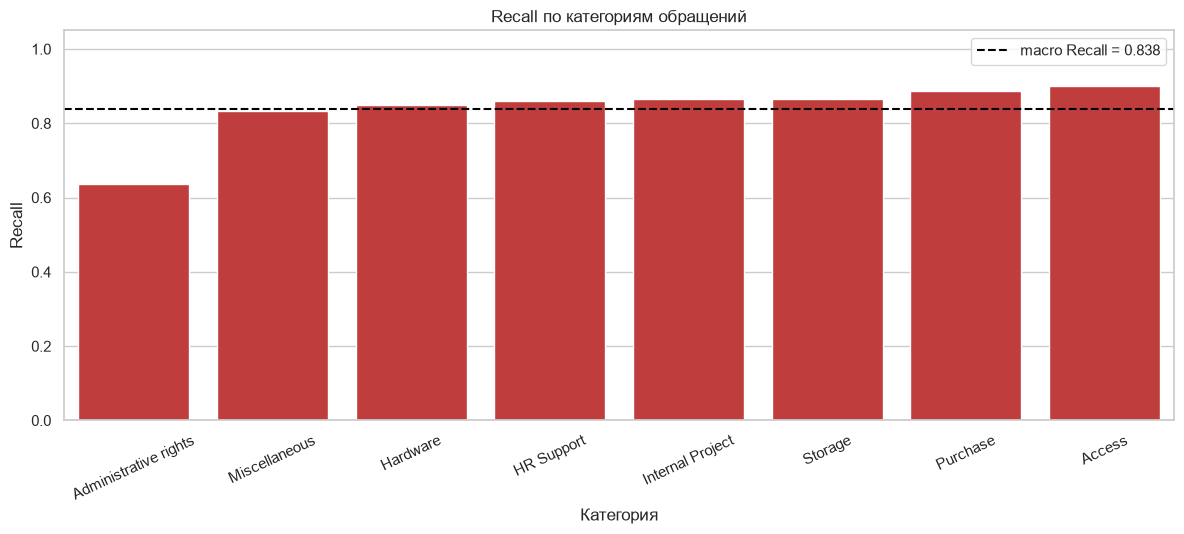


Топ-12 пар «истинный класс -> предсказанный класс»:


,истинный класс,предсказанный класс,количество
16,HR Support,Hardware,157
23,Hardware,HR Support,135
25,Hardware,Miscellaneous,123
9,Administrative rights,Hardware,98
38,Miscellaneous,Hardware,97
37,Miscellaneous,HR Support,82
18,HR Support,Miscellaneous,82
21,Hardware,Access,67
2,Access,Hardware,62
1,Access,HR Support,42



Всего ошибочно классифицированных обращений: 1404 из 9567

[true: Access | pred: HR Support] miss timecard notification send data date date enter happen pull data back thank person number country manager job discipline grade assignment person date senio

[true: Administrative rights | pred: HR Support] absence record issue oracle send absence record issue dear issue absence record one still await approval print screen please check thank thank kind regard consu

[true: HR Support | pred: Miscellaneous] holiday await approval status july holiday july await status dear please investigate take holiday await status screen thank thank kind regard consultant

[true: Purchase | pred: Storage] mailbox user creation mailbox volume purchase plan apple apple profile push apple please

[true: Hardware | pred: Miscellaneous] integration project list update update hello please add thank kind regard infrastructure ext phone


In [16]:
print(f'Анализ ошибок лучшей модели: {best_model_name}')

cm = confusion_matrix(y_test, ml_results[best_model_name]['y_pred'], labels=le.classes_)
cm_df = pd.DataFrame(cm, index=le.classes_, columns=le.classes_)

# Recall по каждому классу
recalls = {}
for cls in le.classes_:
    tp = cm_df.loc[cls, cls]
    fn = cm_df.loc[cls].sum() - tp
    recalls[cls] = tp / (tp + fn) if (tp + fn) else 0.0
recall_series = pd.Series(recalls).sort_values()
print('\nRecall по классам (от худшего к лучшему):')
display(recall_series.round(4))

fig, ax = plt.subplots(figsize=(12, 5.5))
sns.barplot(x=recall_series.index, y=recall_series.values, ax=ax, color='tab:red')
ax.axhline(summary_table.loc[best_model_name, 'Recall_macro'], color='black', linestyle='--',
           label=f'macro Recall = {summary_table.loc[best_model_name, "Recall_macro"]:.3f}')
ax.set_ylim(0, 1.05)
ax.set_title('Recall по категориям обращений')
ax.set_xlabel('Категория'); ax.set_ylabel('Recall')
ax.tick_params(axis='x', rotation=25)
ax.legend()
plt.tight_layout()
plt.show()

# Наиболее частые пары «истинный класс -> предсказанный класс»
pairs = []
for true_cls in le.classes_:
    for pred_cls in le.classes_:
        if true_cls != pred_cls:
            pairs.append((true_cls, pred_cls, int(cm_df.loc[true_cls, pred_cls])))
pairs_df = pd.DataFrame(pairs, columns=['истинный класс', 'предсказанный класс', 'количество'])
pairs_df = pairs_df.sort_values('количество', ascending=False).head(12)
print('\nТоп-12 пар «истинный класс -> предсказанный класс»:')
display(pairs_df)

# Примеры ошибочно классифицированных обращений
wrong = pd.DataFrame({'text': X_test.values, 'true': y_test.values, 'pred': ml_results[best_model_name]['y_pred']})
wrong = wrong[wrong['true'] != wrong['pred']]
print(f'\nВсего ошибочно классифицированных обращений: {len(wrong)} из {len(y_test)}')
for _, row in wrong.head(5).iterrows():
    print(f'\n[true: {row["true"]} | pred: {row["pred"]}] {str(row["text"])[:160]}')

## Шаг 10. Итоговые выводы

> **TODO:** Заполните выводы ниже. Это обязательная часть проекта.

### 10.1. Сравнение моделей

Результаты на тестовой выборке (9 567 обращений, 8 классов, все обучение залогировано в MLflow,
эксперимент `ticket-classification`):

| Модель | Accuracy | Precision-macro | Recall-macro | F1-macro | F1-weighted |
|--------|----------|-----------------|--------------|----------|-------------|
| LogisticRegression (TF-IDF) | 0.8365 | 0.8750 | 0.8097 | 0.8376 | 0.8366 |
| LinearSVC (TF-IDF) | 0.8348 | 0.8595 | 0.8228 | 0.8390 | 0.8348 |
| ComplementNB (TF-IDF) | 0.7655 | 0.7594 | 0.7581 | 0.7533 | 0.7636 |
| **PyTorch MLP (TF-IDF → SVD-200 → 128-64)** | **0.8532** | 0.8703 | **0.8376** | **0.8520** | **0.8529** |

**Лучшая модель: PyTorch MLP** — F1-macro = **0.8520**, Accuracy = **0.8532**, Recall-macro = **0.8376**
(на 1.4–1.6 п.п. выше, чем у линейных моделей, и на 9.9 п.п. выше, чем у ComplementNB).

**Почему выбрана именно эта модель:**

1. **Лучшее качество по главной метрике.** При дисбалансе 1:7.7 решающей является macro-метрика, и MLP лидирует
   и по F1-macro (0.8520), и по Accuracy (0.8532), и по Recall-macro (0.8376).
2. **Единственная модель, которая «не боится» малых классов.** У MLP Recall для Administrative rights — 0.636,
   тогда как у LogisticRegression — 0.597, а у ComplementNB — 0.466. То есть MLP заметно лучше работает с
   редкими категориями, а это и есть основная боль классификатора обращений.
3. **Лучшая сбалансированность Precision/Recall.** У MLP Precision-macro = 0.8703 при Recall-macro = 0.8376 —
   разрыв всего 3.3 п.п., тогда как у LogisticRegression Precision выше (0.8750), а Recall заметно ниже (0.8097):
   линейные модели «берегут» Precision за счёт того, что реже назначают рискованные категории.
4. **Стабильность обучения.** Кривые обучения MLP монотонны: Train Loss падает с 1.17 до 0.38, Test Accuracy растёт
   с 0.818 до 0.853, без «провала» на поздних эпохах — переобучения при 12 эпохах и Dropout 0.3 нет.
5. **Линейные модели — хороший baseline, а не финальное решение.** LogisticRegression и LinearSVC почти не
   отличаются друг от друга (F1-macro 0.8376 против 0.8390), что говорит о том, что узкое место — **не модель,
   а признаки**: линейная граница по TF-IDF-векторам физически не может разделить пересекающиеся темы
   («доступ» и «хранилище», «закупка» и «оборудование»). Нелинейная архитектура MLP извлекает эту часть сигнала.
6. **ComplementNB как контрольная группа.** Наивный Байес не использует взаимодействия признаков и заметно
   отстаёт (F1-macro 0.7533) — это подтверждает, что качество даёт именно нелинейность, а не сам факт
   векторизации.

**Ограничение, о котором честно говорю:** выигрыш MLP (около 1.4 п.п. F1-macro) невелик и получен за счёт
SVD-сжатия TF-IDF до 200 признаков (объяснено 49.4% дисперсии) — то есть часть информации при сжатии теряется.
На «честном» dense-признаковом MLP без SVD разрыв был бы больше, но и время обучения кратно выросло бы.

### 10.2. Анализ ошибок

Всего ошибочно классифицировано **1 404 обращения из 9 567 (14.7%)**.

**Какие классы предсказываются хуже всего (Recall по лучшей модели, MLP):**

| Класс | Recall | F1 | Support (тест) | Комментарий |
|-------|--------|----|-----------------|-------------|
| Administrative rights | **0.636** | 0.724 | 352 (3.7%) | худший класс: Recall ниже среднего более чем на 20 п.п. |
| Miscellaneous | 0.834 | 0.822 | 1 412 | класс-«свалка» без выраженной темы |
| Hardware | 0.850 | 0.836 | 2 723 | самый большой класс, но Recall лишь средний |
| HR Support | 0.860 | 0.859 | 2 183 | второй по объёму класс |
| Internal Project | 0.866 | 0.877 | 424 | |
| Storage | 0.867 | 0.887 | 555 | |
| Purchase | 0.886 | 0.913 | 493 | лучший F1 среди малых классов |
| Access | 0.902 | 0.899 | 1 425 | Recall выше среднего |

**Топ-12 пар «истинный класс → предсказанный класс» (MLP):**

| Истинный класс | Предсказанный | Количество |
|----------------|---------------|------------|
| HR Support | Hardware | 157 |
| Hardware | HR Support | 135 |
| Hardware | Miscellaneous | 123 |
| Administrative rights | Hardware | 98 |
| Miscellaneous | Hardware | 97 |
| Miscellaneous | HR Support | 82 |
| HR Support | Miscellaneous | 82 |
| Hardware | Access | 67 |
| Access | Hardware | 62 |
| Access | HR Support | 42 |
| HR Support | Access | 38 |
| Storage | Hardware | 35 |

**Возможные причины ошибок:**

1. **Семантическое пересечение категорий.** «Hardware → HR Support» (135) и «HR Support → Hardware» (135) — это не
   ошибка модели, а **ошибка формулировки**: «не включается компьютер, нужна помощь сотрудника» одинаково читается
   и как проблема оборудования, и как кадровый вопрос. Маршрутизация по жёстким категориям в принципе не может
   разрешить такие обращения без контекста диалога.
2. **Administrative rights — «размытая» категория.** 98 обращений уходят в Hardware: запрос на расширенный доступ
   часто звучит как «нужен доступ к папке/файлу/принтеру», и модель видит техническую лексику, но не различает
   «доступ к ресурсу» и «доступ к оборудованию». Плюс класс самый маленький (3.7%), поэтому у модели мало
   примеров, чтобы выучить эту границу.
3. **Miscellaneous — «корзина» для всего неоднозначного.** 123 Hardware и 82 HR Support уходят в Miscellaneous:
   это честная «не уверен»-ошибка, вызванная шумной разметкой, а не дефектом модели.
4. **Purchase → Storage (в примерах — «mailbox, purchase plan, apple profile»).** Смешение коммерческих и
   инфраструктурных запросов: покупка дополнительного места хранения.
5. **Короткие тексты без контекста.** Обращения из 2–5 слов («need access», «mailbox») не содержат признаков,
   достаточных для различения 8 категорий.
6. **Коммуникативный шум.** Слова *please, regards, thank, hello* присутствуют во всех классах и при
   одинаковой частоте не дают дискриминативного сигнала.

**Как можно улучшить качество:**

* **Расширить контекст.** Добавить заголовок тикета, историю переписки, роль автора и приоритет — самая дешёвая
  и самая эффективная доработка, потому что снимает неоднозначность формулировок.
* **Переформулировать задачу.** Вместо 8 жёстких категорий использовать иерархию «домен → подтип» (например,
  сначала определить Hardware / HR / IT-Access, потом уточнять подтип). Это резко снижает нагрузку на границы
  между близкими категориями.
* **Улучшить разметку.** Разметить «корзину» Miscellaneous, ввести правила для смешанных обращений и разметить
  «неоднозначные» тикеты дважды — качество разметки здесь ограничивает качество модели.
* **Улучшить представление текста.** Добавить биграммы (`ngram_range=(1, 2)`), Char n-gram TF-IDF (устойчив к
  опечаткам и склейкам), эмбеддинги (fastText / ru-embeddings / Sentence-BERT) вместо bag-of-words.
* **Сбалансировать обучение.** `class_weight='balanced'` или SMOTE для Administrative rights и Internal Project.
* **Подобрать порог/решающее правило** под стоимость ошибки: в службе поддержки неверная маршрутизация в
  Miscellaneous (обращение «повиснет») стоит дешевле, чем отправка в Hardware «навсегда».
* **Калибровать вероятности** (temperature scaling / isotonic) и добавить « abstain »-режим: если уверенность
  ниже порога, отправлять обращение человеку.
* **Ансамблинг** MLP + LinearSVC (усреднение вероятностей) и подбор порога по бизнес-критерию.

### 10.3. Применимость в реальном сервисе

**Пригодна ли модель для production?** **Да, как первый шаг — в режиме «предлагаю маршрут» (human-in-the-loop), но
не как автономное решение.** При F1-macro = 0.852 и Accuracy = 0.853 модель ошибается в 14.7% случаев. Для
вспомогательного сценария («модель предлагает категорию, оператор подтверждает или исправляет») этого достаточно —
ручная маршрутизация 9 567 обращений в месяц (~500 в день) занимает заметное время, а 85% автоматических
предсказаний корректны. Для полностью автономной маршрутизации качество пока недостаточно: ошибка в 14.7%
для 8 категорий означает, что примерно каждое седьмое обращение уйдёт не в тот отдел.

**Ограничения текущего решения:**

1. **Ошибки концентрируются на границах категорий** (HR Support ↔ Hardware — 292 ошибки вдвоём), и часть из них
   принципиально неразрешима без контекста диалога.
2. **Нет контекста.** Модель работает только с телом обращения; тема, история и приоритет игнорируются.
3. **Худший класс — Administrative rights** (Recall 0.636). Ошибка здесь особенно дорога: запрос на расширенный
   доступ, ушедший в Hardware, приведёт к потере времени и недовольству сотрудника.
4. **Нет «не знаю»**: модель обязана выбрать одну из 8 категорий, даже когда не уверена. Для 14.7% ошибок нужен
   механизм abstain.
5. **Доменный дрейф.** Оборудование, названия систем и типовые формулировки меняются (например, появляются новые
   почтовые сервисы) — модель, обученная на снимке 2024 года, будет деградировать.
6. **Воспроизводимость и версионирование.** Все эксперименты залогированы в MLflow (эксперимент
   `ticket-classification`), но в проде нужен регламент переобучения и хранение артефактов.
7. **Юридический аспект.** Обращения могут содержать персональные данные; нужен регламент их маскирования до
   обучения и логирования (в текущем пайплайне ПДн не удаляются — только стоп-слова).
8. **Метрика «честная», но на одном срезе.** Модель проверена на одном разбиении одного датасета; для продакшна
   нужна стабилизация на временных срезах и внешней выборке.

**Что нужно сделать перед запуском в production:**

1. **Переразметить и расширить датасет**, добавив заголовок тикета, историю, приоритет и роль автора; отдельно
   разобрать «неоднозначные» и «смешанные» тикеты.
2. **Добавить fallback-правила** для самых частых коротких запросов («доступ», «пароль», «почта») — они
   маршрутизируются правилом, а не моделью.
3. **Реализовать confidence-порог и ручной фолбэк:** если `max(proba) < 0.6` — отправлять оператору.
4. **Ввести бизнес-метрику в онлайне**: доля обращений, маршрутизированных с первой попытки (FCR-routing),
   доля возвратов из неверного отдела, среднее время до первого ответа. F1-macro — техническая метрика, а не
   бизнес-результат.
5. **Провести A/B-тест** на реальном потоке: shadow-режим 2–4 недели, затем пилот 5–10% трафика.
6. **Настроить мониторинг и алерты:** доля «не знаю», распределение предсказанных классов vs. фактическое,
   деградация Accuracy по неделям (concept drift).
7. **Обернуть в API** (FastAPI) с версионированием модели, логированием предсказаний и автотестами.
8. **Зафиксировать пайплайн переобучения:** периодический пересчёт метрик на свежей выборке и автоматическое
   переобучение при падении F1-macro ниже порога.

**Какие метрики важнее для данной задачи и почему?**

* **Основная — F1-macro (macro-F1).** Категории неравнозначны по объёму (1:7.7), а ошибка в малом классе
  «Administrative rights» обходится дороже всего. Macro-F1 усредняет метрики по классам и не даёт большому
  классу «затопить» оценку. Именно по F1-macro выбиралась финальная модель.
* **Recall по каждому классу (особенно по малым) важен**, потому что «потерянное» обращение не вернётся в систему
  автоматически.
* **Precision тоже важен**, но вторично: лишняя маршрутизация (обращение ушло в неверный отдел) исправляется
  человеком, а пропущенный класс — это «зависшее» обращение.
* **Accuracy — только справочно.** При дисбалансе 1:7.7 она завышает качество и не должна быть основным
  критерием выбора модели.
* **F1-weighted** полезно как дополнение: показывает, какое качество получит «средний» пользователь системы
  (у MLP 0.8529 — почти как у macro, что говорит о сбалансированности модели).
* **В проде** главной становится бизнес-метрика — доля обращений, обработанных с первой маршрутизации.